# Notebook 01 — Diseño matemático y selección del filtro
**Trabajo Práctico Integrador — Filtros analógicos activos (Síntesis de Redes Activas, 2026)**
**Grupo 3 — Tipos: LP y BS — Aproximaciones: Chebyshev I y Elíptica (Cauer)**

Contenido:
1. Especificaciones y conversión a rad/s.
2. Orden mínimo: verificación analítica (ecuaciones de orden de Chebyshev y de grado elíptico) frente a `scipy.signal`.
3. Los cuatro diseños: orden, frecuencias de diseño, polos, ceros, ganancia, $H(s)$ y descomposición en secciones de 1.º/2.º orden.
4. Verificación de especificaciones en los bordes y en **toda** la banda de paso y de rechazo; verificación de que $N-1$ no cumple.
5. Comparación: magnitud, fase desenrollada, retardo de grupo, respuesta al escalón y diagrama de polos y ceros.
6. Tabla comparativa y propuesta de implementación (LP Chebyshev I, orden 3).

Convenciones: frecuencias especificadas en Hz y convertidas a rad/s con $\omega = 2\pi f$. La atenuación se define como
$A(\omega) = -20\log_{10}|H(j\omega)|$ en dB, referida al máximo de $|H|$ (normalización de SciPy: $\max|H(j\omega)| = 1$).

In [1]:
import sys
from pathlib import Path
import numpy as np
import scipy
from scipy import signal, special
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"Matplotlib {matplotlib.__version__} | pandas {pd.__version__}")

# Carpetas de salida (funciona desde notebooks/ del repositorio o desde la raíz en Colab)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG = ROOT / 'figuras'
RES = ROOT / 'resultados'
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

# Estilo de figuras (trazos finos, grilla recesiva, colores categóricos fijos por aproximación)
COLOR = {'cheby1': '#2a78d6', 'ellip': '#eb6834'}
NOMBRE = {'cheby1': 'Chebyshev I', 'ellip': 'Elíptica'}
MASCARA = '#9a9a96'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 9, 'font.family': 'serif',
    'mathtext.fontset': 'cm', 'axes.grid': True, 'grid.color': '#d9d9d6', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#6b6b67', 'axes.linewidth': 0.8, 'lines.linewidth': 1.6,
    'legend.frameon': False, 'axes.spines.top': False, 'axes.spines.right': False,
})

def guardar(fig, nombre):
    """Guarda en PDF (vectorial, para LaTeX) y PNG (para README/notebook)."""
    fig.savefig(FIG / f'{nombre}.pdf', bbox_inches='tight')
    fig.savefig(FIG / f'{nombre}.png', bbox_inches='tight')

Python 3.13.18 | NumPy 2.5.3 | SciPy 1.18.1 | Matplotlib 3.11.2 | pandas 3.0.5


## 1. Especificaciones
| Tipo | Banda(s) de paso | Banda(s) de rechazo |
|---|---|---|
| Pasabajos (LP) | $f \le 1000$ Hz | $f \ge 4000$ Hz |
| Rechazabanda (BS) | $f \le 500$ Hz o $f \ge 5500$ Hz | $1200 \le f \le 2400$ Hz |

$A_p = 1$ dB (atenuación máxima en la banda de paso), $A_s = 24$ dB (atenuación mínima en la banda de rechazo).

In [2]:
AP, AS = 1.0, 24.0
SPECS = {
    'LP': {'wp': [1000], 'ws': [4000], 'btype': 'lowpass'},
    'HP': {'wp': [4000], 'ws': [1000], 'btype': 'highpass'},
    'BP': {'wp': [1200, 2400], 'ws': [500, 5500], 'btype': 'bandpass'},
    'BS': {'wp': [500, 5500], 'ws': [1200, 2400], 'btype': 'bandstop'},
}
GRUPOS = {1: (['LP', 'HP'], ['butter', 'cheby1']), 2: (['HP', 'BP'], ['butter', 'cheby2']),
          3: (['LP', 'BS'], ['cheby1', 'ellip']), 4: (['LP', 'BP'], ['butter', 'bessel'])}
GRUPO = 3
TIPOS, FAMILIAS = GRUPOS[GRUPO]
CASOS = [(t, f) for t in TIPOS for f in FAMILIAS]
print('Casos del grupo', GRUPO, ':', CASOS)

def rad(f_hz):
    """Hz -> rad/s (escalar si la banda tiene un solo borde)."""
    w = 2 * np.pi * np.atleast_1d(np.asarray(f_hz, dtype=float))
    return w[0] if w.size == 1 else w

Casos del grupo 3 : [('LP', 'cheby1'), ('LP', 'ellip'), ('BS', 'cheby1'), ('BS', 'ellip')]


## 2. Orden mínimo — verificación analítica
**Normalización al prototipo pasabajos.** Para el LP, $\Omega_s = \omega_s/\omega_p$. Para el BS se usa la transformación
$s_{LP} = \dfrac{B\,s}{s^2+\omega_0^2}$, con $\omega_0^2 = \omega_{p1}\omega_{p2}$ y $B = \omega_{p2}-\omega_{p1}$, que lleva los bordes
de paso a $\Omega = 1$ y cada borde de rechazo a $\Omega(\omega_s) = \dfrac{B\,\omega_s}{|\omega_0^2-\omega_s^2|}$. El prototipo debe cumplir el
peor caso, $\Omega_s = \min \Omega(\omega_{s,i})$.

**Chebyshev I.** $|H(j\Omega)|^2 = \dfrac{1}{1+\varepsilon^2 C_N^2(\Omega)}$, con $\varepsilon^2 = 10^{A_p/10}-1$:
$$N \ge \frac{\cosh^{-1}\sqrt{D}}{\cosh^{-1}\Omega_s},\qquad D = \frac{10^{A_s/10}-1}{10^{A_p/10}-1}.$$

**Elíptica (ecuación de grado).** Con $k = 1/\Omega_s$ (selectividad) y $k_1 = 1/\sqrt{D}$ (discriminación):
$$N \ge \frac{K(k)\,K(\sqrt{1-k_1^2})}{K(\sqrt{1-k^2})\,K(k_1)},$$
donde $K$ es la integral elíptica completa de primera especie (`scipy.special.ellipk` usa el parámetro $m = k^2$).

**Observación sobre el BS.** Las especificaciones no son geométricamente simétricas: $500\cdot5500 = 2{,}75\cdot10^6\ \mathrm{Hz^2}$ y
$1200\cdot2400 = 2{,}88\cdot10^6\ \mathrm{Hz^2}$. Si se fijan los bordes de paso tal como están especificados, el borde de rechazo de 2400 Hz
queda como peor caso. Como la especificación solo exige paso **hasta** 500 Hz, se puede **ensanchar** la banda de paso inferior
(cumpliendo igual la especificación) hasta $f_{p1}' = 1200\cdot2400/5500 = 523{,}6$ Hz, lo que vuelve simétrico el problema.
Esto es exactamente lo que hacen `cheb1ord`/`ellipord` para bandas: optimizan los bordes de paso.

In [3]:
D = (10**(AS / 10) - 1) / (10**(AP / 10) - 1)
eps = np.sqrt(10**(AP / 10) - 1)

def omega_s_prototipo(tipo, fp=None):
    e = SPECS[tipo]
    fp = np.asarray(e['wp'] if fp is None else fp, float)
    fs = np.asarray(e['ws'], float)
    if tipo == 'LP':
        return fs[0] / fp[0]
    if tipo == 'BS':
        f0sq, B = fp[0] * fp[1], fp[1] - fp[0]
        return np.min(B * fs / np.abs(f0sq - fs**2))
    raise NotImplementedError(tipo)

def N_cheby(Os):
    return np.arccosh(np.sqrt(D)) / np.arccosh(Os)

def N_ellip(Os):
    k, k1 = 1 / Os, 1 / np.sqrt(D)
    K = lambda m: special.ellipk(m)            # parámetro m = k^2
    return K(k**2) * K(1 - k1**2) / (K(1 - k**2) * K(k1**2))

filas = []
for tipo, fp, etiqueta in [('LP', None, 'LP (bordes especificados)'),
                           ('BS', None, 'BS (bordes de paso especificados)'),
                           ('BS', [1200 * 2400 / 5500, 5500], 'BS (borde inferior ensanchado a 523,6 Hz)')]:
    Os = omega_s_prototipo(tipo, fp)
    filas.append({'caso': etiqueta, 'Omega_s': Os,
                  'N_cheby (real)': N_cheby(Os), 'N_cheby': int(np.ceil(N_cheby(Os) - 1e-9)),
                  'N_ellip (real)': N_ellip(Os), 'N_ellip': int(np.ceil(N_ellip(Os) - 1e-9))})
tabla_orden = pd.DataFrame(filas)
print(f'epsilon = {eps:.4f},  sqrt(D) = {np.sqrt(D):.3f}')
tabla_orden.round(4)

epsilon = 0.5088,  sqrt(D) = 31.085


,caso,Omega_s,N_cheby (real),N_cheby,N_ellip (real),N_ellip
0,LP (bordes especificados),4.0000,2.0013,3,1.7496,2
1,BS (bordes de paso especificados),3.9867,2.0047,3,1.7517,2
2,"BS (borde inferior ensanchado a 523,6 Hz)",4.1470,1.9659,2,1.7262,2


Con los bordes del BS tal como se especificaron, Chebyshev I necesitaría un prototipo de orden 3 ($N = 2{,}004$, apenas por encima de 2),
es decir, orden total 6. Ensanchando la banda de paso inferior hasta 523,6 Hz el prototipo de orden 2 alcanza (orden total 4): se ahorra una
sección bicuadrática completa sin violar ninguna especificación. Se adopta el criterio de SciPy y se lo documenta.

## 3. Los cuatro diseños
Funciones `*ord` para el orden mínimo y la frecuencia de diseño `wn` (para Chebyshev I y elíptica, `wn` es el borde de la banda de rizado),
y diseño en forma **ceros–polos–ganancia** (`output='zpk'`), que es numéricamente más robusta que los coeficientes polinomiales.

In [4]:
ORD = {'cheby1': signal.cheb1ord, 'ellip': signal.ellipord}

def disenar(tipo, familia, N=None):
    """Devuelve un dict con el diseño analógico (z, p, k) del caso asignado."""
    e = SPECS[tipo]
    wp, ws = rad(e['wp']), rad(e['ws'])
    Nmin, wn = ORD[familia](wp, ws, AP, AS, analog=True)
    N = Nmin if N is None else N
    if familia == 'cheby1':
        z, p, k = signal.cheby1(N, AP, wn, e['btype'], analog=True, output='zpk')
    elif familia == 'ellip':
        z, p, k = signal.ellip(N, AP, AS, wn, e['btype'], analog=True, output='zpk')
    else:
        raise ValueError(familia)
    return {'tipo': tipo, 'familia': familia, 'N_proto': N, 'N_min': Nmin,
            'wn': np.atleast_1d(wn), 'z': z, 'p': p, 'k': k, 'orden': len(p)}

def H_de(d, f_hz):
    _, H = signal.freqs_zpk(d['z'], d['p'], d['k'], worN=2 * np.pi * np.asarray(f_hz, float))
    return H

DIS = {(t, f): disenar(t, f) for (t, f) in CASOS}
for (t, f), d in DIS.items():
    print(f"{t} {NOMBRE[f]:12s}: N_prototipo = {d['N_proto']}, orden total = {d['orden']}, "
          f"f_diseño = {np.round(d['wn'] / (2 * np.pi), 2)} Hz, k = {d['k']:.6g}")

LP Chebyshev I : N_prototipo = 3, orden total = 3, f_diseño = [1000.] Hz, k = 1.21869e+11
LP Elíptica    : N_prototipo = 2, orden total = 2, f_diseño = [1000.] Hz, k = 0.0630957
BS Chebyshev I : N_prototipo = 2, orden total = 4, f_diseño = [ 523.64 5500.  ] Hz, k = 0.891251
BS Elíptica    : N_prototipo = 2, orden total = 4, f_diseño = [ 523.64 5500.  ] Hz, k = 0.891251


### 3.1 Polos, ceros, estabilidad y secciones
Cada par de polos complejos conjugados $p,\bar p$ define una sección $s^2 + \dfrac{\omega_0}{Q}s + \omega_0^2$ con $\omega_0 = |p|$ y
$Q = \dfrac{|p|}{-2\,\mathrm{Re}\,p}$; un polo real $p=-\sigma$ define una sección de primer orden $s+\sigma$. Los ceros sobre el eje $j\omega$
($\pm j\omega_z$) se asignan al par de polos de $\omega_0$ más cercano (criterio usual de apareamiento). Cada sección se normaliza con
ganancia unitaria en continua; la ganancia restante $H_0 = H(0)$ se informa por separado.

In [5]:
def secciones(d):
    p, z = d['p'], d['z']
    pc = sorted([x for x in p if x.imag > 1e-9 * abs(x)], key=lambda x: abs(x))
    pr = sorted([x.real for x in p if abs(x.imag) <= 1e-9 * abs(x)])
    wz_libres = sorted(set(np.round(np.abs(z[z.imag > 0]), 6)))
    zc = list(np.abs(z[z.imag > 0]))
    secs = []
    for x in pr:
        secs.append({'tipo_sec': '1.er orden', 'f0_Hz': -x / (2 * np.pi), 'Q': np.nan, 'fz_Hz': np.nan,
                     'polo': x})
    for x in pc:
        w0, Q = abs(x), abs(x) / (-2 * x.real)
        fz = np.nan
        if zc:
            i = int(np.argmin([abs(np.log(wz / w0)) for wz in zc]))
            fz = zc.pop(i) / (2 * np.pi)
        secs.append({'tipo_sec': '2.º orden', 'f0_Hz': w0 / (2 * np.pi), 'Q': Q, 'fz_Hz': fz, 'polo': x})
    return pd.DataFrame(secs)

for (t, f), d in DIS.items():
    estable = np.all(d['p'].real < 0)
    H0 = abs(H_de(d, [1e-3])[0])
    d['H0'] = H0
    d['secs'] = secciones(d)
    print(f"\n=== {t} {NOMBRE[f]} — orden {d['orden']} — estable: {estable} — H(0) = {H0:.5f} ({20*np.log10(H0):+.3f} dB)")
    print('Polos  [rad/s]:', np.array2string(np.sort_complex(d['p']), precision=1))
    print('Ceros  [rad/s]:', np.array2string(np.sort_complex(d['z']), precision=1) if len(d['z']) else '— (todos en infinito)')
    print(d['secs'].drop(columns='polo').round(4).to_string(index=False))


=== LP Chebyshev I — orden 3 — estable: True — H(0) = 1.00000 (-0.000 dB)
Polos  [rad/s]: [-3105.    -0.j  -1552.5-6069.5j -1552.5+6069.5j]
Ceros  [rad/s]: — (todos en infinito)
  tipo_sec    f0_Hz      Q  fz_Hz
1.er orden 494.1706    NaN    NaN
 2.º orden 997.0981 2.0177    NaN

=== LP Elíptica — orden 2 — estable: True — H(0) = 0.89125 (-1.000 dB)
Polos  [rad/s]: [-3318.3-5815.9j -3318.3+5815.9j]
Ceros  [rad/s]: [0.-25166.j 0.+25166.j]
 tipo_sec     f0_Hz     Q     fz_Hz
2.º orden 1065.6974 1.009 4005.2893

=== BS Chebyshev I — orden 4 — estable: True — H(0) = 0.89125 (-1.000 dB)
Polos  [rad/s]: [-13995.9-28593.8j -13995.9+28593.8j  -1570.1 -3207.8j  -1570.1 +3207.8j]
Ceros  [rad/s]: [0.-10662.9j 0.-10662.9j 0.+10662.9j 0.+10662.9j]
 tipo_sec     f0_Hz      Q     fz_Hz
2.º orden  568.4112 1.1373 1697.0563
2.º orden 5066.7546 1.1373 1697.0563

=== BS Elíptica — orden 4 — estable: True — H(0) = 0.89125 (-1.000 dB)
Polos  [rad/s]: [-13052.1-28761.9j -13052.1+28761.9j  -1487.6 -3278.j  

### 3.2 Función de transferencia
Se muestran los coeficientes polinomiales (solo como referencia; para el cálculo numérico se usa zpk/secciones). Para el informe se usa la forma
factorizada en secciones con $\omega_0$ y $Q$.

In [6]:
for (t, f), d in DIS.items():
    b, a = signal.zpk2tf(d['z'], d['p'], d['k'])
    b = np.real_if_close(b); a = np.real_if_close(a)
    print(f"\n{t} {NOMBRE[f]}:")
    print('  num:', np.array2string(np.trim_zeros(np.where(abs(b) < 1e-12 * max(abs(b)), 0, b), 'f'), precision=6))
    print('  den:', np.array2string(a, precision=6))


LP Chebyshev I:
  num: [1.218687e+11]
  den: [1.000000e+00 6.209931e+03 4.889043e+07 1.218687e+11]

LP Elíptica:
  num: [6.309573e-02 0.000000e+00 3.996019e+07]
  den: [1.000000e+00 6.636511e+03 4.483607e+07]

BS Chebyshev I:
  num: [2.026666e+08 0.000000e+00 1.152138e+16]
  den: [1.000000e+00 3.113197e+04 1.114146e+09 3.539637e+12 1.292720e+16]

BS Elíptica:
  num: [2.569812e+08 0.000000e+00 1.152138e+16]
  den: [1.000000e+00 2.907931e+04 1.088223e+09 3.306255e+12 1.292720e+16]


**Validación cruzada (Chebyshev I, LP).** Polos analíticos del prototipo:
$p_k = \omega_p\left[-\sinh a\,\sin\theta_k + j\cosh a\,\cos\theta_k\right]$, con $a = \dfrac{1}{N}\sinh^{-1}\dfrac{1}{\varepsilon}$ y
$\theta_k = \dfrac{(2k-1)\pi}{2N}$, $k = 1,\dots,N$.

In [7]:
d = DIS[('LP', 'cheby1')]
N = d['N_proto']; a_ = np.arcsinh(1 / eps) / N
th = (2 * np.arange(1, N + 1) - 1) * np.pi / (2 * N)
p_analitico = rad(1000) * (-np.sinh(a_) * np.sin(th) + 1j * np.cosh(a_) * np.cos(th))
err = np.max(np.abs(np.sort_complex(p_analitico) - np.sort_complex(d['p'])) / np.abs(d['p']))
print('Polos analíticos:', np.round(np.sort_complex(p_analitico), 2))
print('Polos SciPy     :', np.round(np.sort_complex(d['p']), 2))
print(f'Error relativo máximo: {err:.2e}')

Polos analíticos: [-3104.97   +0.j   -1552.48-6069.55j -1552.48+6069.55j]
Polos SciPy     : [-3104.97   -0.j   -1552.48-6069.55j -1552.48+6069.55j]
Error relativo máximo: 3.66e-16


## 4. Verificación de especificaciones
Se evalúa la atenuación en una grilla logarítmica densa que incluye exactamente los bordes, sobre **toda** la banda de paso (desde 1 Hz) y
**toda** la banda de rechazo (hasta 1 MHz). Se verifica además que el diseño con $N_{\text{proto}}-1$ no cumple (orden mínimo).

In [8]:
def bandas(tipo):
    e = SPECS[tipo]
    if tipo == 'LP':
        return [(1.0, e['wp'][0])], [(e['ws'][0], 1e6)]
    if tipo == 'BS':
        return [(1.0, e['wp'][0]), (e['wp'][1], 1e6)], [(e['ws'][0], e['ws'][1])]

def grilla(a, b, n=3000):
    return np.unique(np.concatenate([np.geomspace(a, b, n), [a, b]]))

def verificar(d):
    paso, rech = bandas(d['tipo'])
    A = lambda f: -20 * np.log10(np.abs(H_de(d, f)))
    Ap_max = max(A(grilla(*b)).max() for b in paso)
    As_min = min(A(grilla(*b)).min() for b in rech)
    return Ap_max, As_min, (Ap_max <= AP + 1e-6) and (As_min >= AS - 1e-6)

filas = []
for (t, f), d in DIS.items():
    Ap_max, As_min, ok = verificar(d)
    dm1 = disenar(t, f, N=d['N_proto'] - 1)
    _, As_min_m1, ok_m1 = verificar(dm1)
    bordes = SPECS[t]['wp'] + SPECS[t]['ws']
    Ab = -20 * np.log10(np.abs(H_de(d, bordes)))
    d.update(Ap_max=Ap_max, As_min=As_min, cumple=ok)
    fila = {'caso': f'{t} {NOMBRE[f]}', 'orden': d['orden'], 'A_paso_max [dB]': Ap_max,
            'A_rechazo_min [dB]': As_min, 'margen rechazo [dB]': As_min - AS, 'cumple': ok,
            f'N_proto-1 cumple': ok_m1}
    for fb, ab in zip(bordes, Ab):
        fila[f'A({fb} Hz)'] = ab
    filas.append(fila)
verif = pd.DataFrame(filas)
verif.round(3).T

,0,1,2,3
caso,LP Chebyshev I,LP Elíptica,BS Chebyshev I,BS Elíptica
orden,3,2,4,4
A_paso_max [dB],1.0,1.0,1.0,1.0
A_rechazo_min [dB],41.88,24.0,24.62,24.0
margen rechazo [dB],17.88,0.0,0.62,0.0
cumple,True,True,True,True
N_proto-1 cumple,False,False,False,False
A(1000 Hz),1.0,1.0,NaN,NaN
A(4000 Hz),41.88,75.245,NaN,NaN
A(500 Hz),NaN,NaN,0.651,0.632


**Frecuencias características adicionales.** Frecuencia de −3 dB (LP), frecuencia efectiva donde la atenuación alcanza $A_s$ y ceros de transmisión.

In [9]:
def f_cruce(d, A_obj, f_lo, f_hi):
    """Primera frecuencia en [f_lo, f_hi] donde la atenuación alcanza A_obj (búsqueda + bisección)."""
    f = np.geomspace(f_lo, f_hi, 20000)
    A = -20 * np.log10(np.abs(H_de(d, f)))
    i = np.argmax(A >= A_obj)
    if A[i] < A_obj:
        return np.nan
    lo, hi = f[max(i - 1, 0)], f[i]
    for _ in range(60):
        m = np.sqrt(lo * hi)
        lo, hi = (m, hi) if -20 * np.log10(abs(H_de(d, [m])[0])) < A_obj else (lo, m)
    return np.sqrt(lo * hi)

for (t, f), d in DIS.items():
    fz = np.sort(np.abs(d['z'][d['z'].imag > 0])) / (2 * np.pi) if len(d['z']) else []
    if t == 'LP':
        d['f3dB'] = f_cruce(d, 3.0103, 900, 4000)
        d['fAs'] = f_cruce(d, AS, 1000, 4000)
        print(f"LP {NOMBRE[f]:12s}: f(-3 dB) = {d['f3dB']:.1f} Hz | A = {AS} dB en f = {d['fAs']:.1f} Hz | ceros: {np.round(fz, 1)} Hz")
    else:
        d['fAs'] = (f_cruce(d, AS, 500, 1200), np.nan)
        print(f"BS {NOMBRE[f]:12s}: A = {AS} dB desde f = {d['fAs'][0]:.1f} Hz | ceros: {np.round(fz, 1)} Hz")

LP Chebyshev I : f(-3 dB) = 1094.9 Hz | A = 24.0 dB en f = 2106.8 Hz | ceros: [] Hz
LP Elíptica    : f(-3 dB) = 1199.7 Hz | A = 24.0 dB en f = 2877.4 Hz | ceros: [4005.3] Hz
BS Chebyshev I : A = 24.0 dB desde f = 1186.0 Hz | ceros: [1697.1 1697.1] Hz
BS Elíptica    : A = 24.0 dB desde f = 1039.9 Hz | ceros: [1186.  2428.4] Hz


## 5. Comparación
### 5.1 Magnitud con máscara de especificaciones

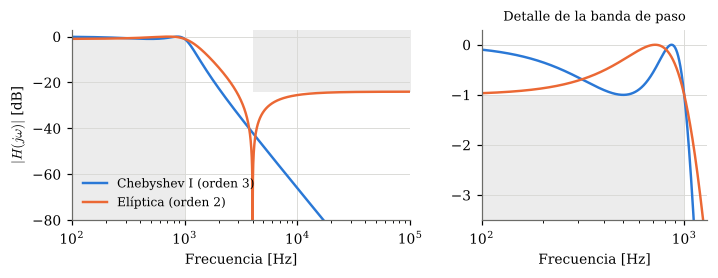

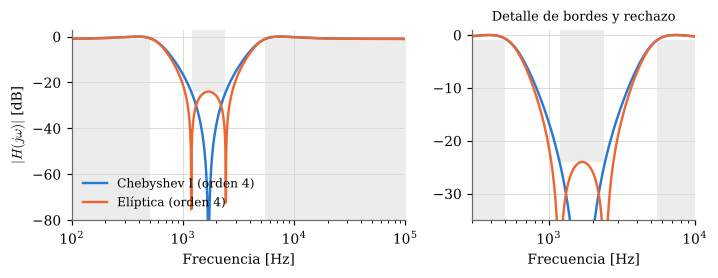

In [10]:
def mascara(ax, tipo, ymin):
    e = SPECS[tipo]
    # Se sombrean solo las regiones PROHIBIDAS: |H| < -Ap en paso y |H| > -As en rechazo
    kw = dict(color=MASCARA, alpha=0.18, lw=0)
    if tipo == 'LP':
        ax.fill_between([1, e['wp'][0]], ymin, -AP, **kw)
        ax.fill_between([e['ws'][0], 1e6], -AS, 5, **kw)
    else:
        for a, b in [(1, e['wp'][0]), (e['wp'][1], 1e6)]:
            ax.fill_between([a, b], ymin, -AP, **kw)
        ax.fill_between(e['ws'], -AS, 5, **kw)

def fig_magnitud(tipo, f_rango, zoom, nombre):
    f = np.geomspace(*f_rango, 4000)
    fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.6), gridspec_kw={'width_ratios': [1.5, 1]})
    for fam in FAMILIAS:
        d = DIS[(tipo, fam)]
        g = 20 * np.log10(np.abs(H_de(d, f)))
        lab = f"{NOMBRE[fam]} (orden {d['orden']})"
        axs[0].semilogx(f, g, color=COLOR[fam], label=lab)
        fz = np.geomspace(*zoom['f'], 3000)
        axs[1].semilogx(fz, 20 * np.log10(np.abs(H_de(d, fz))), color=COLOR[fam])
    mascara(axs[0], tipo, -90); mascara(axs[1], tipo, -90)
    axs[0].set(xlim=f_rango, ylim=(-80, 3), xlabel='Frecuencia [Hz]', ylabel='$|H(j\\omega)|$ [dB]')
    axs[1].set(xlim=zoom['f'], ylim=zoom['y'], xlabel='Frecuencia [Hz]', title=zoom['titulo'])
    axs[0].legend(loc='lower left', fontsize=8)
    axs[1].title.set_fontsize(8.5)
    fig.tight_layout(); guardar(fig, nombre); plt.show()

fig_magnitud('LP', (100, 1e5), {'f': (100, 1300), 'y': (-3.5, 0.3), 'titulo': 'Detalle de la banda de paso'}, 'fig_LP_magnitud')
fig_magnitud('BS', (100, 1e5), {'f': (300, 10000), 'y': (-35, 1), 'titulo': 'Detalle de bordes y rechazo'}, 'fig_BS_magnitud')

### 5.2 Fase desenrollada y retardo de grupo
El retardo de grupo se calcula **analíticamente** a partir de polos y ceros, en rad/s:
$$\tau_g(\omega) = -\frac{d\varphi}{d\omega} = \sum_{i}\frac{-\sigma_{p_i}}{\sigma_{p_i}^2+(\omega-\omega_{p_i})^2} \;-\; \sum_{j}\frac{-\sigma_{z_j}}{\sigma_{z_j}^2+(\omega-\omega_{z_j})^2},$$
con $p_i = \sigma_{p_i}+j\omega_{p_i}$ y $z_j = \sigma_{z_j}+j\omega_{z_j}$. Los ceros sobre el eje $j\omega$ ($\sigma_z = 0$) no aportan retardo salvo en $\omega = \omega_z$,
donde la fase salta $\pm 180^\circ$ (cambio de signo de $H$): esos saltos son reales y no son errores del desenrollado. En el BS Chebyshev I los
ceros son dobles, el salto es de $360^\circ$ y `np.unwrap` lo elimina (por eso su fase se ve continua). Se contrasta con la derivada
numérica $-\Delta\varphi/\Delta\omega$ (con $\omega$ en rad/s, no en Hz).

LP Chebyshev I : error relativo máx. analítico vs numérico (50–800 Hz) = 2.2e-06
LP Elíptica    : error relativo máx. analítico vs numérico (50–800 Hz) = 9.3e-07
BS Chebyshev I : error relativo máx. analítico vs numérico (50–800 Hz) = 3.0e-06
BS Elíptica    : error relativo máx. analítico vs numérico (50–800 Hz) = 3.4e-06


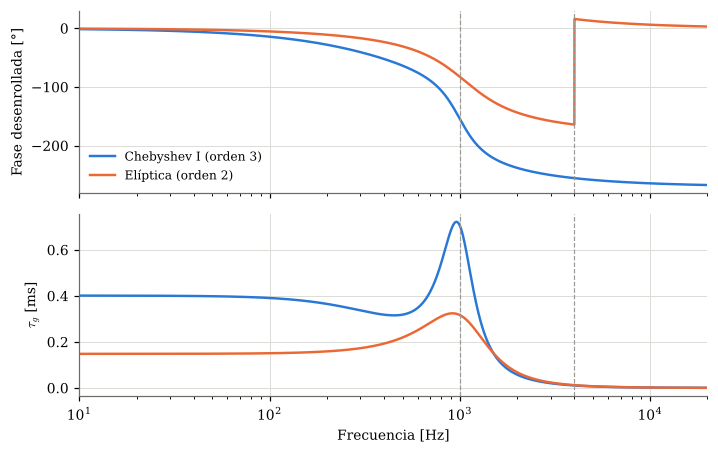

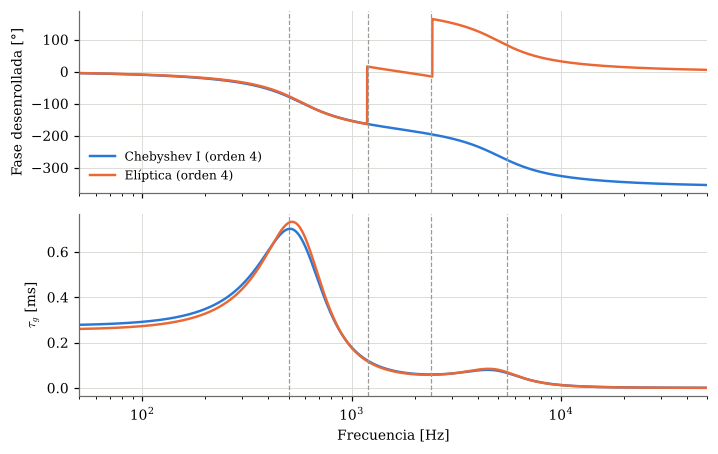

In [11]:
def retardo_grupo(d, f_hz):
    w = 2 * np.pi * np.asarray(f_hz, float)
    tau = np.zeros_like(w)
    for p in d['p']:
        tau += -p.real / (p.real**2 + (w - p.imag)**2)
    for z in d['z']:
        if abs(z.real) > 1e-9 * max(abs(z), 1):
            tau -= -z.real / (z.real**2 + (w - z.imag)**2)
    return tau

# Contraste analítico vs numérico (lejos de ceros jω)
for (t, fam), d in DIS.items():
    fchk = np.geomspace(50, 800, 2000)
    H = H_de(d, fchk)
    tau_num = -np.gradient(np.unwrap(np.angle(H)), 2 * np.pi * fchk)
    e = np.max(np.abs(tau_num - retardo_grupo(d, fchk))[5:-5] / retardo_grupo(d, fchk)[5:-5])
    print(f'{t} {NOMBRE[fam]:12s}: error relativo máx. analítico vs numérico (50–800 Hz) = {e:.1e}')

def fig_fase_retardo(tipo, f_rango, nombre):
    f = np.geomspace(*f_rango, 6000)
    fig, axs = plt.subplots(2, 1, figsize=(6.6, 4.2), sharex=True)
    for fam in FAMILIAS:
        d = DIS[(tipo, fam)]
        fase = np.degrees(np.unwrap(np.angle(H_de(d, f))))
        axs[0].semilogx(f, fase, color=COLOR[fam], label=f"{NOMBRE[fam]} (orden {d['orden']})")
        axs[1].semilogx(f, 1e3 * retardo_grupo(d, f), color=COLOR[fam])
    for ax in axs:
        for fb in SPECS[tipo]['wp'] + SPECS[tipo]['ws']:
            ax.axvline(fb, color=MASCARA, lw=0.8, ls='--')
    axs[0].set(ylabel='Fase desenrollada [°]')
    axs[1].set(ylabel='$\\tau_g$ [ms]', xlabel='Frecuencia [Hz]', xlim=f_rango)
    axs[0].legend(fontsize=8, loc='lower left')
    fig.tight_layout(); guardar(fig, nombre); plt.show()

fig_fase_retardo('LP', (10, 2e4), 'fig_LP_fase_retardo')
fig_fase_retardo('BS', (50, 5e4), 'fig_BS_fase_retardo')

### 5.3 Respuesta al escalón (comportamiento temporal)

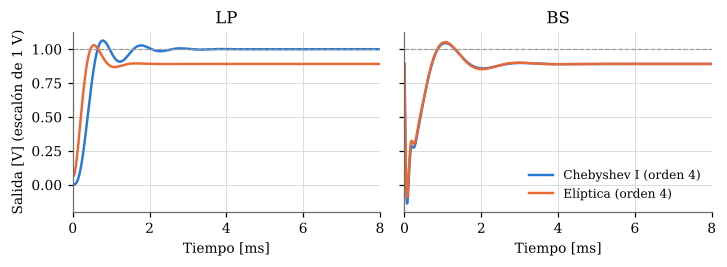

In [12]:
def escalon(d, T):
    t, y = signal.step(signal.ZerosPolesGain(d['z'], d['p'], d['k']), T=T)
    return t, y

def metricas_escalon(d, T):
    t, y = escalon(d, T)
    yf = d['H0']
    sobre = 100 * (y.max() - yf) / yf
    fuera = np.where(np.abs(y - yf) > 0.02 * yf)[0]
    ts = t[fuera[-1] + 1] if len(fuera) and fuera[-1] + 1 < len(t) else np.nan
    if d['tipo'] == 'LP':
        tr = t[np.argmax(y >= 0.9 * yf)] - t[np.argmax(y >= 0.1 * yf)]
    else:
        tr = np.nan
    return sobre, ts, tr

T = np.linspace(0, 8e-3, 8001)
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.5), sharey=True)
for ax, tipo in zip(axs, TIPOS):
    for fam in FAMILIAS:
        d = DIS[(tipo, fam)]
        t, y = escalon(d, T)
        ax.plot(1e3 * t, y, color=COLOR[fam], label=f"{NOMBRE[fam]} (orden {d['orden']})")
        d['sobrepico'], d['ts'], d['tr'] = metricas_escalon(d, T)
    ax.axhline(1, color=MASCARA, lw=0.8, ls='--')
    ax.set(xlabel='Tiempo [ms]', title=f'{tipo}', xlim=(0, 8))
axs[0].set_ylabel('Salida [V] (escalón de 1 V)')
axs[1].legend(fontsize=8, loc='lower right')
fig.tight_layout(); guardar(fig, 'fig_escalon'); plt.show()

### 5.4 Diagrama de polos y ceros (en kHz, $s/2\pi$)

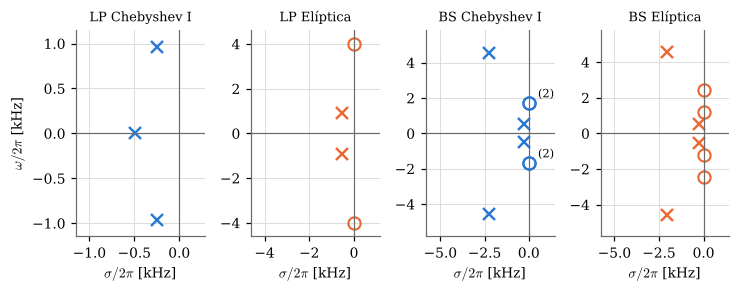

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(6.8, 2.6))
for ax, (t, fam) in zip(axs, CASOS):
    d = DIS[(t, fam)]
    s = 1e-3 / (2 * np.pi)
    ax.plot(d['p'].real * s, d['p'].imag * s, 'x', color=COLOR[fam], ms=8, mew=1.6, label='polos')
    if len(d['z']):
        ax.plot(d['z'].real * s, d['z'].imag * s, 'o', mfc='none', color=COLOR[fam], ms=8, mew=1.4, label='ceros')
        zu, cnt = np.unique(np.round(d['z'][d['z'].imag > 0], 3), return_counts=True)
        for zz, c in zip(zu, cnt):
            if c > 1:   # multiplicidad (ceros dobles del BS Chebyshev I)
                ax.annotate(f'({c})', (zz.real * s, zz.imag * s), xytext=(6, 4), textcoords='offset points', fontsize=7.5)
                ax.annotate(f'({c})', (zz.real * s, -zz.imag * s), xytext=(6, 4), textcoords='offset points', fontsize=7.5)
    lim = 1.15 * max(np.abs(np.concatenate([d['p'], d['z']])) * s)
    ax.set(xlim=(-lim, 0.25 * lim), ylim=(-lim, lim), title=f'{t} {NOMBRE[fam]}', xlabel='$\\sigma/2\\pi$ [kHz]')
    ax.axvline(0, color='#6b6b67', lw=0.8); ax.axhline(0, color='#6b6b67', lw=0.8)
    ax.set_aspect('equal'); ax.title.set_fontsize(8.5)
axs[0].set_ylabel('$\\omega/2\\pi$ [kHz]')
fig.tight_layout(); guardar(fig, 'fig_polos_ceros'); plt.show()

### 5.5 Tabla comparativa

In [14]:
TOPOLOGIA = {
    ('LP', 'cheby1'): 'RC 1.er orden + Sallen–Key LP (2 AO)',
    ('LP', 'ellip'):  'Bicuadrática con ceros jω (LPN): KHN + sumador o Boctor',
    ('BS', 'cheby1'): '2 bicuadráticas notch (ceros dobles en f0)',
    ('BS', 'ellip'):  '2 bicuadráticas notch LPN/HPN (fz ≠ f0)',
}
filas = []
for (t, fam), d in DIS.items():
    f = np.geomspace(1, 1e5, 20000)
    tau = retardo_grupo(d, f)
    paso, _ = bandas(t)
    fpas = np.concatenate([grilla(*b) for b in paso])
    tau_pas = retardo_grupo(d, fpas)
    filas.append({
        'Caso': f'{t} {NOMBRE[fam]}', 'Orden': d['orden'],
        'H(0) [dB]': 20 * np.log10(d['H0']),
        'A paso máx [dB]': d['Ap_max'], 'A rechazo mín [dB]': d['As_min'],
        'Q máx': np.nanmax(d['secs']['Q']),
        'Ceros finitos': 'sí' if len(d['z']) else 'no',
        'tau_g(0) [ms]': 1e3 * retardo_grupo(d, [0.0])[0],
        'tau_g máx en paso [ms]': 1e3 * tau_pas.max(),
        'Variación tau_g en paso [ms]': 1e3 * (tau_pas.max() - tau_pas.min()),
        'Sobrepico [%]': d['sobrepico'], 't_s 2% [ms]': 1e3 * d['ts'],
        'Topología sugerida': TOPOLOGIA[(t, fam)],
    })
comp = pd.DataFrame(filas)
comp.to_csv(RES / 'tabla_comparativa.csv', index=False)
comp.round(3).T

,0,1,2,3
Caso,LP Chebyshev I,LP Elíptica,BS Chebyshev I,BS Elíptica
Orden,3,2,4,4
H(0) [dB],-0.0,-1.0,-1.0,-1.0
A paso máx [dB],1.0,1.0,1.0,1.0
A rechazo mín [dB],41.88,24.0,24.62,24.0
Q máx,2.018,1.009,1.137,1.21
Ceros finitos,no,sí,sí,sí
tau_g(0) [ms],0.401,0.148,0.274,0.256
tau_g máx en paso [ms],0.722,0.324,0.701,0.728
Variación tau_g en paso [ms],0.406,0.176,0.701,0.728


## 6. Elección del filtro y propuesta de implementación
**Filtro elegido: LP Chebyshev I de orden 3** (propuesta de la cátedra, sujeta a aprobación docente). Argumentos:
1. **Cumple con margen amplio:** a 4 kHz atenúa ≈ 42 dB frente a los 24 dB exigidos (≈ 18 dB de margen), lo que absorbe la dispersión de componentes
   (relevante para el Monte Carlo del Nivel II). El elíptico de orden 2 cumple con margen nulo en la banda de rechazo: su atenuación asintótica es exactamente $A_s$.
2. **Todo polos:** se realiza con una sección de 1.er orden y una bicuadrática pasabajos (Sallen–Key, Daryanani cap. 8), sin necesidad de ceros sobre
   $j\omega$. El elíptico requiere una bicuadrática con ceros de transmisión (más amplificadores y alta sensibilidad de $f_z$).
3. **Orden impar:** $H(0) = 0$ dB (el rizado queda por debajo de 0 dB); los diseños de orden par tienen $H(0) = -1$ dB.
4. **Q moderado (≈ 2,02):** realizable con un AO de la familia TL08x sin exigencias de GBW críticas (se verifica en la semana 2).

Costo: mayor retardo de grupo y sobrepico que el elíptico de orden 2 (se cuantifica en la tabla y es la motivación natural del ecualizador del Nivel III).

**Distribución en secciones y orden de cascada.** La sección de 2.º orden tiene un pico propio de $\approx Q/\sqrt{1-1/4Q^2}$ cerca de $f_0$; si se
colocara primera, su salida interna superaría a la salida final. Se coloca **primero la sección de 1.er orden** (atenúa antes del pico) y después la
bicuadrática, verificando el nivel máximo en el nodo intermedio.

  tipo_sec    f0_Hz      Q  fz_Hz
1.er orden 494.1706    NaN    NaN
 2.º orden 997.0981 2.0177    NaN

Error |T1·T2 - H_t| máximo: 7.11e-16
Pico de la bicuadrática sola: 6.37 dB en 934 Hz (teórico Q/sqrt(1-1/4Q^2) = 6.37 dB)
Máximo en el nodo intermedio si T2 va primero: +6.37 dB; si T1 va primero: -0.00 dB


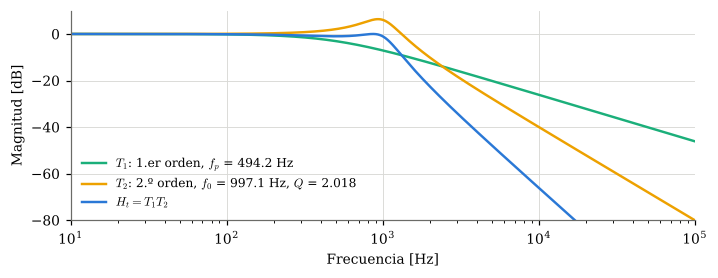

In [15]:
d = DIS[('LP', 'cheby1')]
sec = d['secs']
print(sec.drop(columns='polo').round(4).to_string(index=False))
f = np.geomspace(10, 1e5, 4000)
w = 2 * np.pi * f
s = 1j * w
p1 = sec.loc[sec.tipo_sec == '1.er orden', 'polo'].values[0].real
fila2 = sec[sec.tipo_sec == '2.º orden'].iloc[0]
w0, Q = 2 * np.pi * fila2.f0_Hz, fila2.Q
T1 = -p1 / (s - p1)
T2 = w0**2 / (s**2 + s * w0 / Q + w0**2)
Ht = H_de(d, f)
print(f'\nError |T1·T2 - H_t| máximo: {np.max(np.abs(T1 * T2 - Ht)):.2e}')
pico_T2 = np.max(np.abs(T2)); f_pico = f[np.argmax(np.abs(T2))]
print(f'Pico de la bicuadrática sola: {20*np.log10(pico_T2):.2f} dB en {f_pico:.0f} Hz '
      f'(teórico Q/sqrt(1-1/4Q^2) = {20*np.log10(Q/np.sqrt(1-1/(4*Q**2))):.2f} dB)')
print(f'Máximo en el nodo intermedio si T2 va primero: {20*np.log10(pico_T2):+.2f} dB; '
      f'si T1 va primero: {20*np.log10(np.max(np.abs(T1))):+.2f} dB')

fig, ax = plt.subplots(figsize=(6.6, 2.6))
ax.semilogx(f, 20 * np.log10(np.abs(T1)), color='#1baf7a', label=f'$T_1$: 1.er orden, $f_p$ = {-p1/2/np.pi:.1f} Hz')
ax.semilogx(f, 20 * np.log10(np.abs(T2)), color='#eda100', label=f'$T_2$: 2.º orden, $f_0$ = {fila2.f0_Hz:.1f} Hz, $Q$ = {Q:.3f}')
ax.semilogx(f, 20 * np.log10(np.abs(Ht)), color=COLOR['cheby1'], label='$H_t = T_1T_2$')
ax.set(xlim=(10, 1e5), ylim=(-80, 10), xlabel='Frecuencia [Hz]', ylabel='Magnitud [dB]')
ax.legend(fontsize=8, loc='lower left')
fig.tight_layout(); guardar(fig, 'fig_LP_cheby1_secciones'); plt.show()

## 7. Exportación para el informe (tablas LaTeX)

In [16]:
def num(x, nd=2):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return '---'
    x = 0.0 if abs(x) < 0.5 * 10**(-nd) else x          # evita '-0,00'
    txt = f'{abs(x):.{nd}f}'.replace('.', '{,}')
    return ('$-$' + txt) if x < 0 else txt              # signo menos tipográfico

lineas = [r'\begin{tabular}{@{}lcccccc@{}}', r'\toprule',
          r'Caso & Orden & $H(0)$ [dB] & $A_{p,\max}$ [dB] & $A_{s,\min}$ [dB] & $Q_{\max}$ & Ceros finitos \\', r'\midrule']
for r in filas:
    lineas.append(f"{r['Caso']} & {r['Orden']} & {num(r['H(0) [dB]'])} & {num(r['A paso máx [dB]'], 3)} & "
                  f"{num(r['A rechazo mín [dB]'])} & {num(r['Q máx'], 3)} & {r['Ceros finitos']} \\\\")
lineas += [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_comparativa_magnitud.tex').write_text('\n'.join(lineas), encoding='utf-8')

lineas = [r'\begin{tabular}{@{}lcccc@{}}', r'\toprule',
          r'Caso & $\tau_g(0)$ [ms] & $\tau_{g,\max}$ paso [ms] & $\Delta\tau_g$ paso [ms] & Sobrepico [\%] \\', r'\midrule']
for r in filas:
    lineas.append(f"{r['Caso']} & {num(r['tau_g(0) [ms]'], 3)} & {num(r['tau_g máx en paso [ms]'], 3)} & "
                  f"{num(r['Variación tau_g en paso [ms]'], 3)} & {num(r['Sobrepico [%]'], 1)} \\\\")
lineas += [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_comparativa_tiempo.tex').write_text('\n'.join(lineas), encoding='utf-8')

lineas = [r'\begin{tabular}{@{}llccc@{}}', r'\toprule',
          r'Caso & Sección & $f_0$ [Hz] & $Q$ & $f_z$ [Hz] \\', r'\midrule']
for (t, fam), d in DIS.items():
    for i, r in d['secs'].reset_index(drop=True).iterrows():
        caso = f'{t} {NOMBRE[fam]}' if i == 0 else ''
        lineas.append(f"{caso} & {r.tipo_sec} & {num(r.f0_Hz, 1)} & {num(r.Q, 3)} & {num(r.fz_Hz, 1)} \\\\")
    lineas.append(r'\addlinespace')
lineas = lineas[:-1] + [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_secciones.tex').write_text('\n'.join(lineas), encoding='utf-8')

lineas = [r'\begin{tabular}{@{}lcccccc@{}}', r'\toprule',
          r'Caso & $\Omega_s$ & $N_\mathrm{Cheb}$ (real) & $N_\mathrm{Cheb}$ & $N_\mathrm{ellip}$ (real) & $N_\mathrm{ellip}$ \\', r'\midrule']
for _, r in tabla_orden.iterrows():
    lineas.append(f"{r.caso} & {num(r.Omega_s, 3)} & {num(r['N_cheby (real)'], 3)} & {r.N_cheby} & "
                  f"{num(r['N_ellip (real)'], 3)} & {r.N_ellip} \\\\")
lineas += [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_orden.tex').write_text('\n'.join(lineas).replace('lcccccc', 'lccccc'), encoding='utf-8')

# Tabla de verificación transpuesta: filas = criterios, columnas = casos
cols = list(DIS.keys())
cab = ' & '.join(f'{t} {NOMBRE[fam]}' for t, fam in cols)
lineas = [r'\begin{tabular}{@{}l' + 'c' * len(cols) + '@{}}', r'\toprule', f'Criterio & {cab} \\\\', r'\midrule']
def celda_borde(d, fb, rol):
    e = SPECS[d['tipo']]
    if fb not in e[rol]:
        return '---'
    return num(-20 * np.log10(abs(H_de(d, [fb])[0])), 2)
for rol, etiqueta in [('wp', 'paso'), ('ws', 'rechazo')]:
    bordes = sorted(set(sum((SPECS[t][rol] for t in TIPOS), [])))
    for fb in bordes:
        lineas.append(f'$A$({fb} Hz) [dB], borde de {etiqueta} & ' + ' & '.join(celda_borde(DIS[c], fb, rol) for c in cols) + r' \\')
lineas.append(r'\midrule')
lineas.append(r'$A_{p,\max}$ en toda la banda de paso [dB] & ' + ' & '.join(num(DIS[c]['Ap_max'], 3) for c in cols) + r' \\')
lineas.append(r'$A_{s,\min}$ en toda la banda de rechazo [dB] & ' + ' & '.join(num(DIS[c]['As_min'], 2) for c in cols) + r' \\')
lineas.append(r'Margen $A_{s,\min}-A_s$ [dB] & ' + ' & '.join(num(DIS[c]['As_min'] - AS, 2) for c in cols) + r' \\')
lineas.append(r'Cumple la plantilla & ' + ' & '.join('sí' if DIS[c]['cumple'] else 'no' for c in cols) + r' \\')
lineas.append(r'Cumple con $N_\mathrm{proto}-1$ & ' + ' & '.join(
    'sí' if verif.loc[verif.caso == f"{c[0]} {NOMBRE[c[1]]}", 'N_proto-1 cumple'].values[0] else 'no' for c in cols) + r' \\')
lineas += [r'\bottomrule', r'\end{tabular}']
(RES / 'tab_verificacion.tex').write_text('\n'.join(lineas), encoding='utf-8')

# Resumen numérico para el informe (valores que se citan en el texto)
resumen = []
for (t, fam), d in DIS.items():
    resumen.append({'caso': f'{t}_{fam}', 'orden': d['orden'], 'wn_Hz': ';'.join(f'{x/2/np.pi:.3f}' for x in d['wn']),
                    'k': d['k'], 'H0': d['H0'], 'Ap_max': d['Ap_max'], 'As_min': d['As_min'],
                    'polos': ';'.join(f'{x:.4f}' for x in np.sort_complex(d['p'])),
                    'ceros': ';'.join(f'{x:.4f}' for x in np.sort_complex(d['z']))})
pd.DataFrame(resumen).to_csv(RES / 'disenos_zpk.csv', index=False)
print('Exportado:', sorted(x.name for x in RES.iterdir()))

Exportado: ['disenos_zpk.csv', 'tab_comparativa_magnitud.tex', 'tab_comparativa_tiempo.tex', 'tab_orden.tex', 'tab_secciones.tex', 'tab_verificacion.tex', 'tabla_comparativa.csv']
